# AOD spectra example for a few campaigns per coast distance

**Name:** Proposal_AERO_COAST_AOD_spectra

**Purpose:**  
Make some figures of the AOD spectra for a few different campaigns from 4STAR to show the spectra aat coast, over land, and a certain distance from coast.

**Input:**  
- SEAC4RS
- AirSHARP
- KORUS-AQ

**Output:** Maps and histograms displayed inline and saved as PNG files  

**Dependencies:** `numpy`, `scipy`, `matplotlib`, `cartopy`, `shapely`, `geopandas`, `netCDF4`, `pandas`  

**History:**  
Written: Samuel LeBlanc, Santa Cruz, CA, 2026-11-17  
Updated: ...


# Prepare the Python Environment

In [2]:
import os
import glob
import warnings
import numpy as np
import pandas as pd
import netCDF4 as nc
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker
from matplotlib.path import Path as MplPath
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from scipy.spatial import cKDTree
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.shapereader as shpreader
import shapely.geometry as sgeom
warnings.filterwarnings('ignore')

In [2]:
%matplotlib inline

# Paths and Configuration

In [3]:
fp_airsharp = '/data/sunsat/AirSHARP_2024/data_archival/AOD_R0_nc/'
fp_seac4rs = '/data/sunsat/SEAC4RS_2013/data_processed/starsuns/R2_20150908/'
fp_korus = '/data/sunsat/KORUSAQ_2016/data_processed/starsuns/R2_processed_202208/'

In [4]:
# California coast bounding box for spatial filtering
CA_LON_MIN, CA_LON_MAX = -130.0, -113.0
CA_LAT_MIN, CA_LAT_MAX =   30.0,   44.0

# Monterey Bay zoom box
MB_LON_MIN, MB_LON_MAX = -123.5, -120.5
MB_LAT_MIN, MB_LAT_MAX =   35.5,   38.0

# Build Distance-to-Coast Tools

**Magnitude** — KD-tree built from Natural Earth 10 m coastline, densified to ≈0.005°
spacing (≈500 m), converted to km using a flat-Earth approximation centred on the
California domain.  

**Sign** — Land mask rasterised at 0.02° (≈2 km) onto the California grid using
`matplotlib.path.Path.contains_points`.  Sign is −1 if the point is over land,
+1 if over water.  The sign from the satellite flag bits is used directly for PACE
and VIIRS pixels (faster and consistent with each product's own surface classification).

In [129]:
def build_distance_tools(bounds=(CA_LON_MIN, CA_LON_MAX, CA_LAT_MIN, CA_LAT_MAX),
                         resolution='10m'):
    """Build KD-tree and land-mask raster for signed distance-to-coast computation.
    
    Returns
    -------
    kd        : scipy cKDTree, queryable in km-projected coordinates
    scale     : array([km_per_deg_lon, km_per_deg_lat]) for coordinate conversion
    is_land_grid : bool 2-D array (lat × lon) at 0.02° resolution
    lon_r, lat_r : 1-D coordinate arrays for the land-mask grid
    """
    lon_min, lon_max, lat_min, lat_max = bounds
    lat0  = (lat_min + lat_max) / 2.0
    scale = np.array([111.32 * np.cos(np.radians(lat0)), 111.32])  # km / degree
    box_geom = sgeom.box(lon_min - 1, lat_min - 1, lon_max + 1, lat_max + 1)

    # --- Coastline → densified points → KD-tree ---
    print('  Building coastline KD-tree...')
    coast_path = shpreader.natural_earth(resolution, 'physical', 'coastline')
    raw_segs = []
    for geom in shpreader.Reader(coast_path).geometries():
        if not geom.intersects(box_geom):
            continue
        segs = [geom] if geom.geom_type == 'LineString' else list(geom.geoms)
        for seg in segs:
            coords = np.array(seg.coords)
            # Densify each segment to ~0.005° spacing
            for k in range(len(coords) - 1):
                d_deg = np.hypot(*(coords[k + 1] - coords[k]))
                n = max(2, int(d_deg / 0.005) + 1)
                raw_segs.append(np.linspace(coords[k], coords[k + 1], n))
    if not raw_segs:
        raise RuntimeError('No coastline found in bounds')
    coast_pts = np.vstack(raw_segs)  # shape (N, 2) lon/lat
    kd = cKDTree(coast_pts * scale)  # in km
    print(f'    {len(coast_pts):,} coastline points in KD-tree')

    # --- Land polygons → raster mask ---
    print('  Building land-mask raster...')
    lon_r = np.arange(lon_min, lon_max + 0.02, 0.02)
    lat_r = np.arange(lat_min, lat_max + 0.02, 0.02)
    LO, LA = np.meshgrid(lon_r, lat_r)
    grid_pts = np.column_stack([LO.ravel(), LA.ravel()])
    is_land_flat = np.zeros(len(grid_pts), dtype=bool)

    land_path = shpreader.natural_earth(resolution, 'physical', 'land')
    for geom in shpreader.Reader(land_path).geometries():
        if not geom.intersects(box_geom):
            continue
        polys = [geom] if geom.geom_type == 'Polygon' else list(geom.geoms)
        for poly in polys:
            ext = np.array(poly.exterior.coords)
            p = MplPath(ext)
            is_land_flat |= p.contains_points(grid_pts)

    is_land_grid = is_land_flat.reshape(LA.shape)
    print(f'    Land mask: {LA.shape} grid ({is_land_flat.sum():,} / {len(grid_pts):,} land cells)')
    return kd, scale, is_land_grid, lon_r, lat_r


print('Building distance tools (one-time setup)...')
kd_coast, scale_km, is_land_grid, lon_r, lat_r = build_distance_tools()
print('Done.')

Building distance tools (one-time setup)...
  Building coastline KD-tree...
    50,323 coastline points in KD-tree
  Building land-mask raster...
    Land mask: (702, 851) grid (282,210 / 597,402 land cells)
Done.


In [130]:
def dist_to_coast_km(lats, lons, sign_from_flag=None):
    """Compute signed distance to nearest coastline in km.
    
    Parameters
    ----------
    lats, lons       : array-like of geographic coordinates
    sign_from_flag   : bool array, True = over land (negative distance).
                       If None, determined from the land-mask raster.
    
    Returns
    -------
    dist : float array, km.  Positive = over water, negative = over land.
    """
    lats = np.asarray(lats, dtype=float)
    lons = np.asarray(lons, dtype=float)
    valid = np.isfinite(lats) & np.isfinite(lons)

    dist = np.full(len(lats), np.nan)
    if valid.any():
        pts_km = np.column_stack([lons[valid], lats[valid]]) * scale_km
        dist[valid], _ = kd_coast.query(pts_km)

    # Determine sign
    if sign_from_flag is not None:
        is_land = np.asarray(sign_from_flag, dtype=bool)
    else:
        # Lookup in raster via nearest grid index
        lon_idx = np.searchsorted(lon_r, lons, side='right') - 1
        lat_idx = np.searchsorted(lat_r, lats, side='right') - 1
        in_grid = (
            valid &
            (lon_idx >= 0) & (lon_idx < len(lon_r)) &
            (lat_idx >= 0) & (lat_idx < len(lat_r))
        )
        is_land = np.zeros(len(lats), dtype=bool)
        is_land[in_grid] = is_land_grid[lat_idx[in_grid], lon_idx[in_grid]]

    dist[is_land] *= -1
    return dist

# Load the various campaign data

## Load the AirSHARP

In [131]:
import load_utils as lu

In [132]:
fa = fp_airsharp+'AirSHARP-4STARB-AOD_AirSHARP-TO_20241007_R0.nc'

In [133]:
air,air_hdr = lu.load_netcdf(fa,everything=True)

Reading file: /data/sunsat/AirSHARP_2024/data_archival/AOD_R0_nc/AirSHARP-4STARB-AOD_AirSHARP-TO_20241007_R0.nc
Outputting the Data subdatasets:
0: qual_flag
1: Latitude
2: Longitude
3: GPS_Alt
4: wavelength
5: day_of_year
6: UTC_time
7: AOD
8: AOD_uncertainty
9: m_aero
10: AOD_angstrom_470_865
11: FMF
[b'qual_flag', b'Latitude', b'Longitude', b'GPS_Alt', b'wavelength', b'day_of_year', b'UTC_time', b'AOD', b'AOD_uncertainty', b'm_aero', b'AOD_angstrom_470_865', b'FMF']


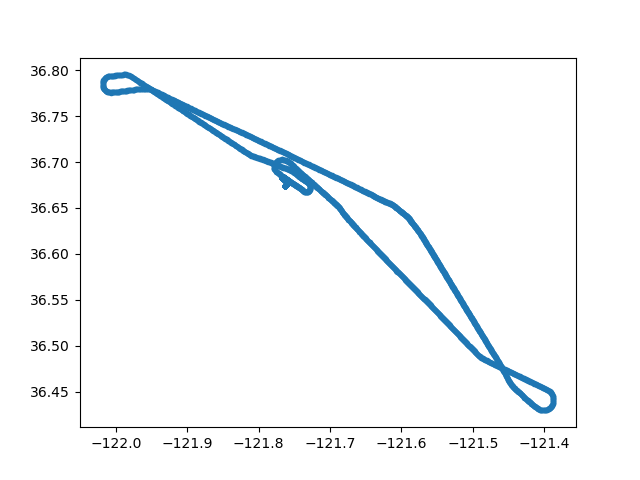

In [134]:
plt.figure()
plt.plot(air[b'Longitude'],air[b'Latitude'],'.')

In [135]:
air_coast = dist_to_coast_km(air[b'Latitude'], air[b'Longitude'])

In [136]:
air_coast

array([-4.93717473, -4.93717473, -4.93717473, ..., -4.66461552,
       -4.66461552, -4.66461552], shape=(9032,))

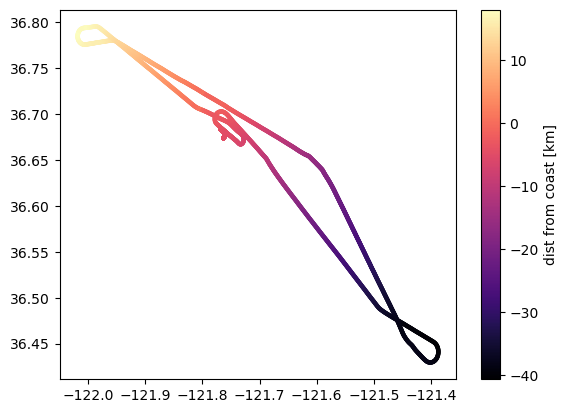

In [29]:
plt.figure()
plt.plot(air[b'Longitude'],air[b'Latitude'],'-')
plt.scatter(air[b'Longitude'],air[b'Latitude'],5,c=air_coast,marker='o',cmap=plt.cm.magma,zorder=5)
plt.colorbar(label='dist from coast [km]')

(7000.0, 8500.0)

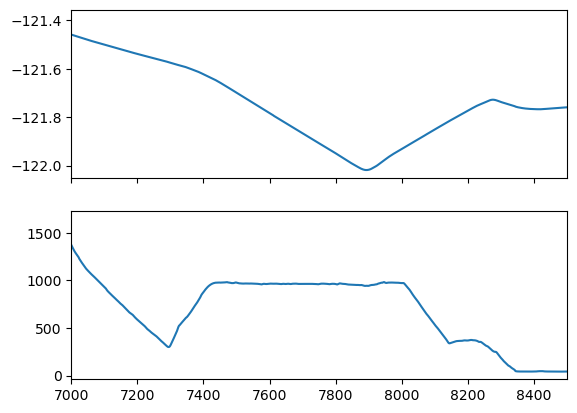

In [33]:
fig,ax = plt.subplots(2,1,sharex=True)
ax[0].plot(air[b'Longitude'])
ax[1].plot(air[b'GPS_Alt'])
ax[1].set_xlim(7000,8500)

In [139]:
iland = 7300
icoast = 8150
iocean = 7900

In [140]:
air_coast[iland],air_coast[icoast],air_coast[iocean]

(np.float64(-20.070790569912887),
 np.float64(0.1472671568015691),
 np.float64(17.925245520938855))

In [141]:
from scipy.stats import binned_statistic

In [58]:
def binned_median_iqr(x, y, bins):
    """Return bin centres, medians, 25th and 75th percentiles."""
    ok = np.isfinite(x) & np.isfinite(y)
    x, y = x[ok], y[ok]
    med, _, _  = binned_statistic(x, y, statistic='median', bins=bins)
    p25, _, _  = binned_statistic(x, y, statistic=lambda v: np.percentile(v, 25), bins=bins)
    p75, _, _  = binned_statistic(x, y, statistic=lambda v: np.percentile(v, 75), bins=bins)
    cnt, _, _  = binned_statistic(x, y, statistic='count',  bins=bins)
    mask = cnt < 10
    med[mask] = np.nan
    p25[mask] = np.nan
    p75[mask] = np.nan
    return 0.5 * (bins[:-1] + bins[1:]), med, p25, p75, cnt

In [21]:
def plot_aod_sp(wvl,aod,i,di=10,label='',color='g'):
    'plot simple spectra, with shading and smoothing'
    plt.plot(wvl,aod[:,i],'-',color=color,label=label)
    aa = np.nanstd(aod[:,i-di:i+di],axis=1)
    plt.fill_between(wvl, aod[:,i]-aa,aod[:,i]+aa,
                color=color, alpha=0.2, label='_nolegend_')

In [37]:
from scipy.ndimage import uniform_filter1d

def plot_aod_spm(wvl, aod, i, di=10, win=5, label='', color='g'):
    'plot simple spectra, with shading and smoothing'
    # Smooth along wavelength axis (axis=0) while ignoring NaNs
    valid = np.isfinite(aod[:, i])
    y = uniform_filter1d(np.where(valid, aod[:, i], 0.0), win) / uniform_filter1d(valid.astype(float), win)
    
    plt.plot(wvl, y, '-', color=color, label=label)
    aa = np.nanstd(aod[:, i-di:i+di], axis=1)
    plt.fill_between(wvl, y - aa, y + aa, color=color, alpha=0.2, label='_nolegend_')


In [50]:
def plot_aod_spp(wvl, aod, i, di=10, deg=2, label='', color='g',percentile=False):
    'plot simple spectra, with shading and smoothing'
    plt.plot(wvl,aod[:,i],'.',color=color,label='_nolegend_')
    y_raw = aod[:, i]
    m = np.isfinite(wvl) & np.isfinite(y_raw) & (y_raw > 0)
    
    # Fit polynomial in log(wvl) vs log(aod) space
    p = np.polyfit(np.log(wvl[m]), np.log(y_raw[m]), deg=deg)
    y = np.exp(np.polyval(p, np.log(wvl)))
    
    plt.plot(wvl, y, '-', color=color, label=label)
    
    if percentile:
        p25, p75 = np.nanpercentile(aod[:, max(0, i-di):i+di], [25, 75], axis=1)
        plt.fill_between(wvl, p25, p75, color=color, alpha=0.2, label='_nolegend_')
    else:
        aa = np.nanstd(aod[:, i-di:i+di], axis=1)
        plt.fill_between(wvl, aod[:,i]-aa, aod[:,i]+aa, color=color, alpha=0.2, label='_nolegend_')


Text(0.5, 1.0, 'AirSHARP 2024-10-07')

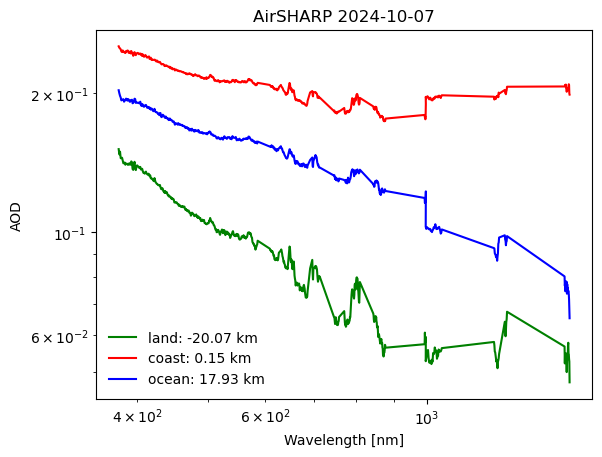

In [57]:
plt.figure()
plt.plot(air[b'wavelength'],air[b'AOD'][:,iland],'-',color='g',label=f'land: {air_coast[iland]:2.2f} km')
plt.plot(air[b'wavelength'],air[b'AOD'][:,icoast],'-',color='r',label=f'coast: {air_coast[icoast]:2.2f} km')
plt.plot(air[b'wavelength'],air[b'AOD'][:,iocean],'-',color='b',label=f'ocean: {air_coast[iocean]:2.2f} km')
plt.yscale('log')
plt.xscale('log')
plt.legend(frameon=False)
plt.xlabel('Wavelength [nm]')
plt.ylabel('AOD')
plt.title('AirSHARP 2024-10-07')

Text(0.5, 1.0, 'AirSHARP 2024-10-07')

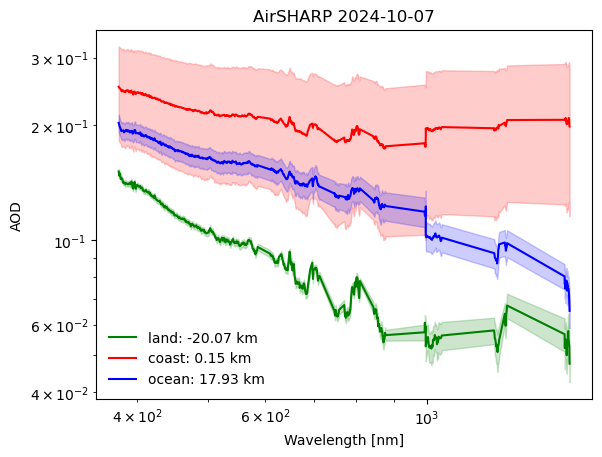

In [66]:
plt.figure()
plot_aod_sp(air[b'wavelength'],air[b'AOD'],iland,color='g',label=f'land: {air_coast[iland]:2.2f} km')
plot_aod_sp(air[b'wavelength'],air[b'AOD'],icoast,color='r',label=f'coast: {air_coast[icoast]:2.2f} km')
plot_aod_sp(air[b'wavelength'],air[b'AOD'],iocean,color='b',label=f'ocean: {air_coast[iocean]:2.2f} km')
#plt.plot(air[b'wavelength'],air[b'AOD'][:,iland],'-',color='g',label=f'land: {air_coast[iland]:2.2f} km')
#plt.plot(air[b'wavelength'],air[b'AOD'][:,icoast],'-',color='r',label=f'coast: {air_coast[icoast]:2.2f} km')
#plt.plot(air[b'wavelength'],air[b'AOD'][:,iocean],'-',color='b',label=f'ocean: {air_coast[iocean]:2.2f} km')
plt.yscale('log')
plt.xscale('log')
plt.legend(frameon=False)
plt.xlabel('Wavelength [nm]')
plt.ylabel('AOD')
plt.title('AirSHARP 2024-10-07')

## Now load the SEAC4RS example

In [5]:
os.listdir(fp_seac4rs)

['20130819starsun_R2_tauaero.mat',
 '20130816starsun_R2_tauaero.mat',
 '20130827starsun_R2_o3.mat',
 '20130909starsun_R2.mat',
 '20130906starsun_R2_tauaero.mat',
 '20130808starsun_R2_tauaero.mat',
 '20130909starsun_R2_tauaero.mat',
 '20130911starsun_R2_tauaero.mat',
 '20130821starsun_R2_tauaero.mat',
 '20130906starsun_R2.mat',
 '20130904starsun_R2_tauaero.mat',
 '20130923starsun_R2_tauaero.mat',
 '20130913starsun_R2_tauaero.mat',
 '20130826starsun_R2_tauaero.mat',
 '20130823starsun_R2.mat',
 '20130816starsun_R2.mat',
 '20130921starsun_R2_tauaero.mat',
 '20130918starsun_R2_tauaero.mat',
 '20130806starsun_R2.mat',
 '20130814starsun_R2.mat',
 '20130921starsun_R2.mat',
 '20130812starsun_R2_tauaero.mat',
 '20130904starsun_R2.mat',
 '20130826starsun_R2.mat',
 '20130902starsun_R2_tauaero.mat',
 'logs_20150908',
 '20130911starsun_R2.mat',
 '20130814starsun_R2_tauaero.mat',
 '20130913starsun_R2.mat',
 '20130808starsun_R2.mat',
 '20130819starsun_R2.mat',
 '20130902starsun_R2.mat',
 '20130821star

In [6]:
import scipy.io as sio

In [7]:
seacr = sio.loadmat(fp_seac4rs+'20130918starsun_R2.mat')

In [8]:
seacr.keys()

dict_keys(['__header__', '__version__', '__globals__', 't', 'raw', 'Str', 'Md', 'Zn', 'Lat', 'Lon', 'Alt', 'Headng', 'pitch', 'roll', 'Tst', 'Pst', 'RH', 'AZstep', 'Elstep', 'AZ_deg', 'El_deg', 'QdVlr', 'QdVtb', 'QdVtot', 'AZcorr', 'ELcorr', 'Tbox', 'Tprecon', 'RHprecon', 'filename', 'note', 'ng', 'O3h', 'O3col', 'NO2col', 'sd_aero_crit', 'c0mod', 'w', 'c0', 'c0err', 'fwhm', 'aerosolcols', 'skyresp', 'aeronetcols', 'skyresperr', 'sat_time', 'sat_ij', 'rawcorr', 'rate', 'dark', 'darkstd', 'viscols', 'nircols', 'vist', 'nirt', 'visVdettemp', 'nirVdettemp', 'visTint', 'nirTint', 'visAVG', 'nirAVG', 'visheader', 'nirheader', 'visrow_labels', 'nirrow_labels', 'visfilen', 'nirfilen', 'vissat_pixel', 'nirsat_pixel', 'sunaz', 'sunel', 'sza', 'f', 'm_ray', 'm_aero', 'm_H2O', 'RHprecon_percent', 'Tprecon_C', 'Tbox_C', 'visVdettemp_C', 'nirVdettemp_C', 'm_O3', 'm_NO2', 'tau_ray', 'tau_r_err', 'tau_O3', 'tau_NO2', 'tau_O4', 'tau_CO2_CH4_N2O', 'tau_O3_err', 'tau_NO2_err', 'tau_O4_err', 'tau_CO2_CH4

In [10]:
seacr['w']

array([[0.173182  , 0.173975  , 0.174768  , ..., 1.70183969, 1.70301446,
        1.70301   ]], shape=(1, 1556))

In [11]:
seacr['tau_aero'][:,400]

array([       nan,        nan,        nan, ..., 5.33995539, 5.82181858,
              nan], shape=(23900,))

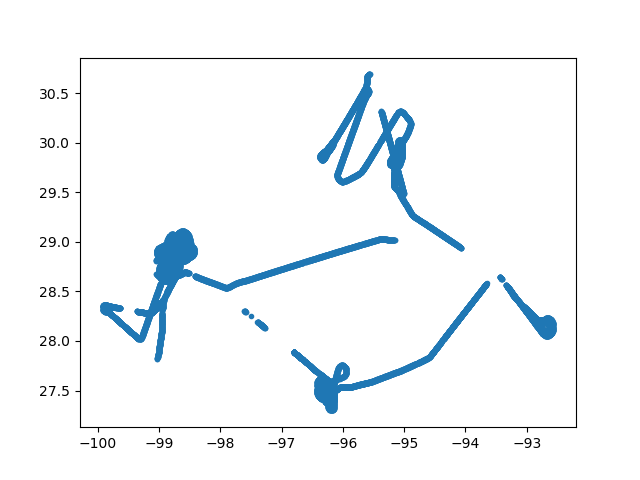

In [12]:
plt.figure()
plt.plot(seacr['Lon'],seacr['Lat'],'.')

In [13]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt

In [66]:
def make_map(extent=[-100, -92, 27.0, 30.8]):
    proj = ccrs.PlateCarree()
    fig, ax = plt.subplots(figsize=(8, 6), subplot_kw={"projection": proj})
    
    # Extent: [lon_min, lon_max, lat_min, lat_max] covering Houston to the Gulf
    ax.set_extent(extent, crs=proj)
    
    # Add high-resolution physical and political features
    ax.add_feature(cfeature.OCEAN.with_scale("10m"), facecolor="#d4ebf2")
    ax.add_feature(cfeature.LAND.with_scale("10m"), facecolor="#f2efe9")
    ax.add_feature(cfeature.COASTLINE.with_scale("10m"), linewidth=0.8, edgecolor="#333333")
    ax.add_feature(cfeature.BORDERS.with_scale("10m"), linewidth=0.6)
    ax.add_feature(cfeature.STATES.with_scale("10m"), linewidth=0.5, edgecolor="#666666")
    
    # Plot Houston marker and label
    ax.plot(-95.3698, 29.7604, "ro", markersize=6, transform=proj)
    ax.text(-95.32, 29.80, "Houston", fontsize=10, fontweight="bold", transform=proj)
    
    # Add lat/lon gridlines
    gl = ax.gridlines(draw_labels=True, linewidth=0.4, color="gray", alpha=0.5, linestyle="--")
    gl.top_labels = False
    gl.right_labels = False
    
    #plt.plot(seacr['Lon'],seacr['Lat'],'.')
    
    plt.tight_layout()
    #plt.show()
    return fig,ax,proj

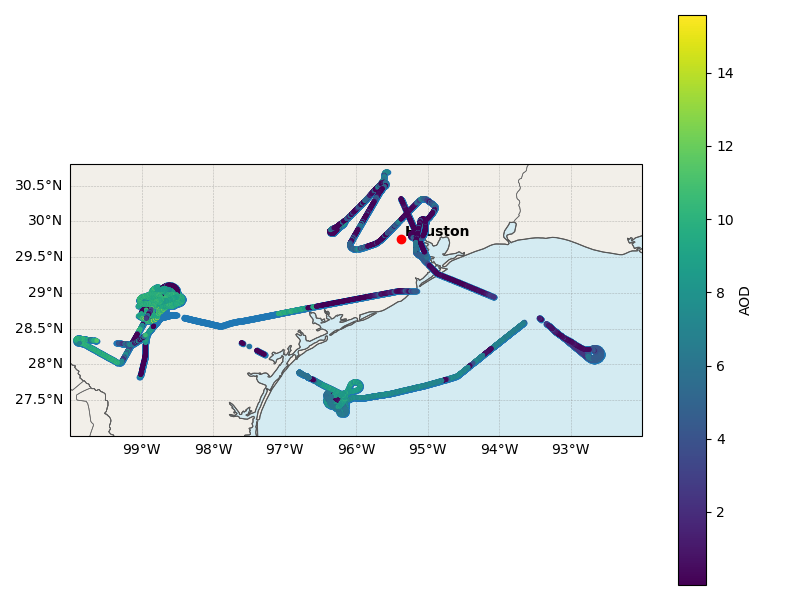

In [15]:
fig,ax,proj = make_map()
ax.plot(seacr['Lon'],seacr['Lat'],'.',zorder=5,transform=proj)
psc = ax.scatter(seacr['Lon'],seacr['Lat'],5,marker='o',c=seacr['tau_aero'][:,400],zorder=20,transform=proj)
plt.colorbar(psc,label='AOD')


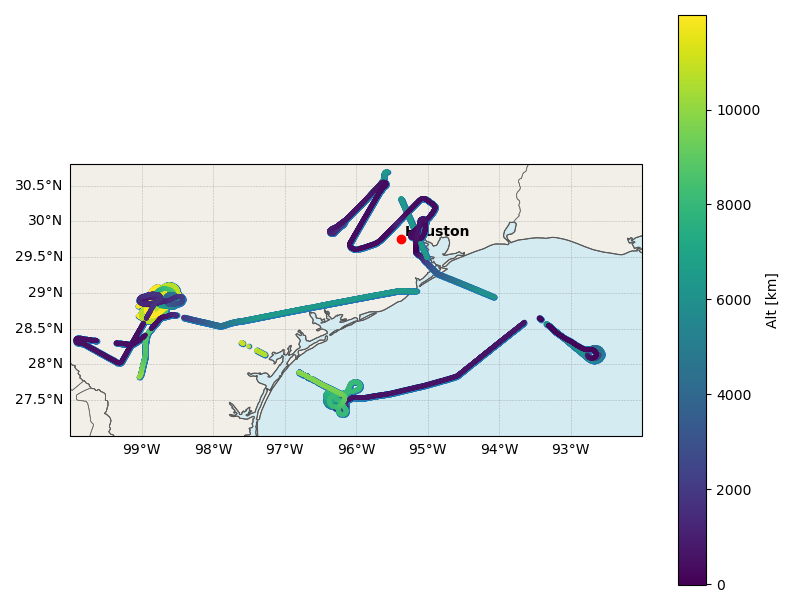

In [16]:
fig,ax,proj = make_map()
ax.plot(seacr['Lon'],seacr['Lat'],'.',zorder=5,transform=proj)
psc = ax.scatter(seacr['Lon'],seacr['Lat'],5,marker='o',c=seacr['Alt'],zorder=20,transform=proj)
plt.colorbar(psc,label='Alt [km]')

In [34]:
ilands = 21104
icoasts = 5052
ioceans = 6465

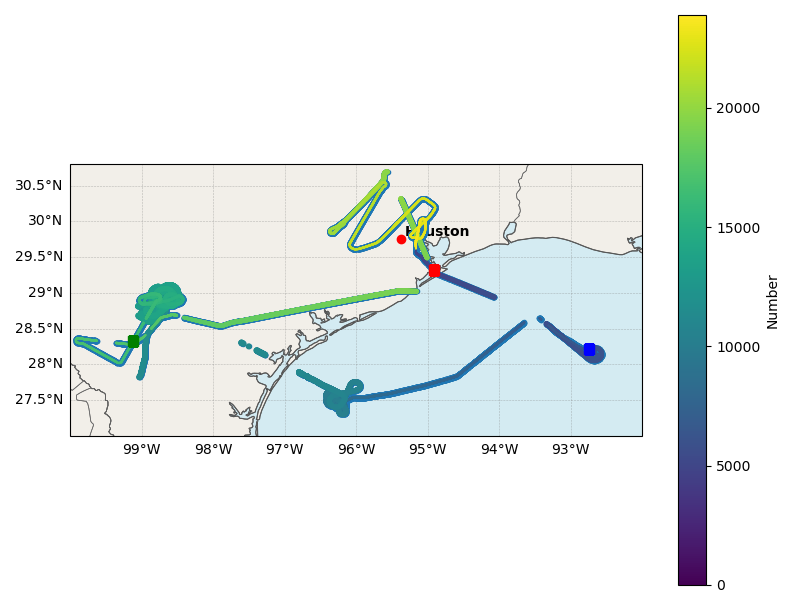

In [19]:
fig,ax,proj = make_map()
ax.plot(seacr['Lon'],seacr['Lat'],'.',zorder=5,transform=proj)
psc = ax.scatter(seacr['Lon'],seacr['Lat'],seacr['Alt']/1000,marker='o',c=np.arange(len(seacr['Alt'])),zorder=20,transform=proj)
ax.scatter(seacr['Lon'][ilands],seacr['Lat'][ilands],60,marker='s',c='g',zorder=25,transform=proj)
ax.scatter(seacr['Lon'][icoasts],seacr['Lat'][icoasts],60,marker='s',c='r',zorder=25,transform=proj)
ax.scatter(seacr['Lon'][ioceans],seacr['Lat'][ioceans],60,marker='s',c='b',zorder=25,transform=proj)
plt.colorbar(psc,label='Number')

Text(0.5, 1.0, 'SEAC4RS 2013-09-18')

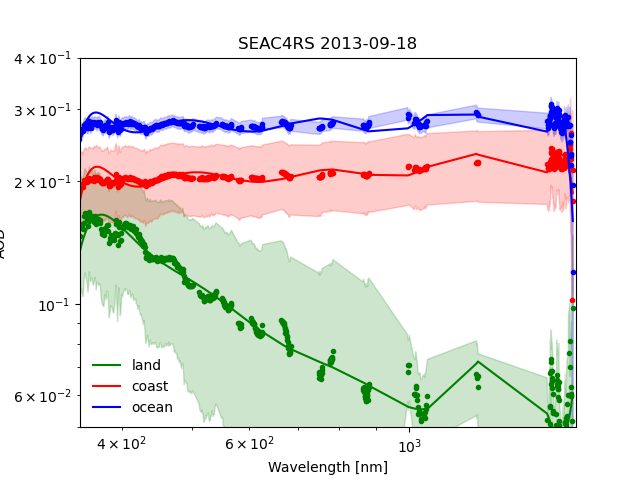

In [54]:
plt.figure()
wvl = seacr['w'][0,seacr['aerosolcols'][0,:]]*1000
aod = seacr['tau_aero'].T[seacr['aerosolcols'][0,:],:]
plot_aod_spp(wvl,aod,ilands,color='g',deg=20,label=f'land')# : {air_coast[iland]:2.2f} km')
plot_aod_spp(wvl,aod,icoasts,color='r',deg=20,label=f'coast')# : {air_coast[icoast]:2.2f} km')
plot_aod_spp(wvl,aod,ioceans,color='b',deg=20,label=f'ocean')# : {air_coast[iocean]:2.2f} km')
#plt.plot(air[b'wavelength'],air[b'AOD'][:,iland],'-',color='g',label=f'land: {air_coast[iland]:2.2f} km')
#plt.plot(air[b'wavelength'],air[b'AOD'][:,icoast],'-',color='r',label=f'coast: {air_coast[icoast]:2.2f} km')
#plt.plot(air[b'wavelength'],air[b'AOD'][:,iocean],'-',color='b',label=f'ocean: {air_coast[iocean]:2.2f} km')
plt.yscale('log')
plt.xscale('log')
plt.legend(frameon=False)
plt.xlabel('Wavelength [nm]')
plt.xlim(350,1700)
plt.ylim(0.05,0.4)
plt.ylabel('AOD')
plt.title('SEAC4RS 2013-09-18')

Text(0.5, 1.0, 'SEAC4RS 2013-09-18')

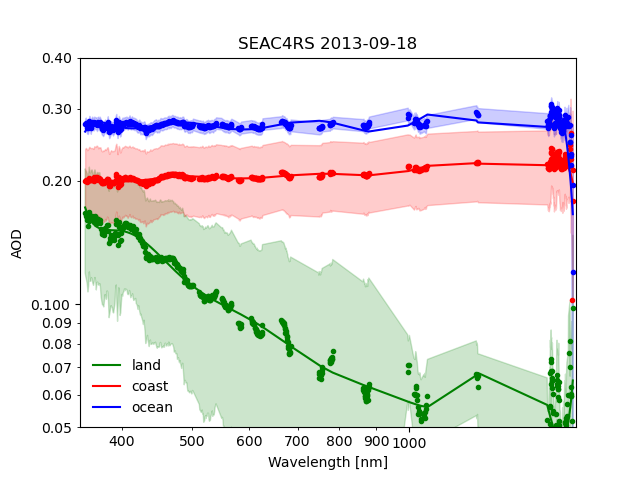

In [58]:
import matplotlib.ticker as ticker

plt.figure()
wvl = seacr['w'][0, seacr['aerosolcols'][0, 46:]] * 1000
aod = seacr['tau_aero'].T[seacr['aerosolcols'][0, 46:], :]

plot_aod_spp(wvl, aod, ilands, color='g', deg=20, label='land')
plot_aod_spp(wvl, aod, icoasts, color='r', deg=20, label='coast')
plot_aod_spp(wvl, aod, ioceans, color='b', deg=20, label='ocean')

plt.yscale('log')
plt.xscale('log')
plt.xlim(350, 1700)
plt.ylim(0.05, 0.4)

# Format both major and minor ticks as plain numbers (no scientific notation)
ax = plt.gca()
for axis in [ax.xaxis, ax.yaxis]:
    fmt = ticker.ScalarFormatter()
    fmt.set_scientific(False)
    axis.set_major_formatter(fmt)
    axis.set_minor_formatter(fmt)

plt.legend(frameon=False)
plt.xlabel('Wavelength [nm]')
plt.ylabel('AOD')
plt.title('SEAC4RS 2013-09-18')


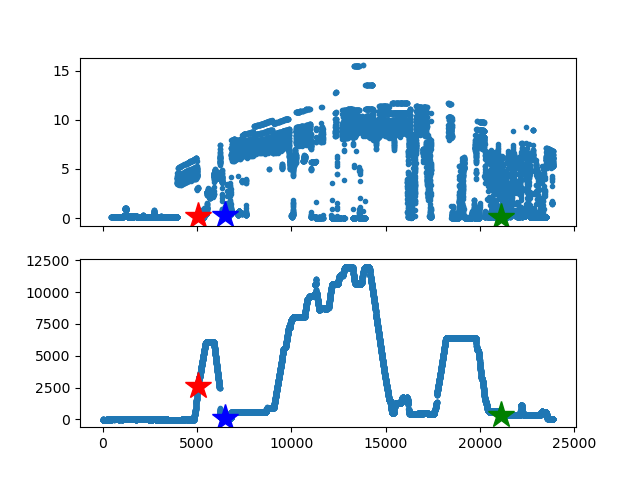

In [35]:
fig,ax = plt.subplots(2,1,sharex=True)
ax[0].plot(seacr['tau_aero'][:,400],'.')
ax[0].plot(ilands,seacr['tau_aero'][ilands,400],'*g',markersize=20)
ax[0].plot(icoasts,seacr['tau_aero'][icoasts,400],'*r',markersize=20)
ax[0].plot(ioceans,seacr['tau_aero'][ioceans,400],'*b',markersize=20)
ax[1].plot(seacr['Alt'],'.')
ax[1].plot(ilands,seacr['Alt'][ilands],'*g',markersize=20)
ax[1].plot(icoasts,seacr['Alt'][icoasts],'*r',markersize=20)
ax[1].plot(ioceans,seacr['Alt'][ioceans],'*b',markersize=20)
#plt.xlim(16000,17500)
#plt.xlim(16000,17500)

## Now load the KORUS example

In [63]:
import mat73

In [59]:
os.listdir(fp_korus)

['4STAR_20160519starsun_small.mat',
 '4STAR_20160521starsun_small.mat',
 '4STAR_20160521starsun.mat',
 '4STAR_20160524starsun_small.mat',
 '4STAR_20160519starsun.mat',
 '4STAR_20160510starsun_for_starflag.mat',
 '4STAR_20160524starsun.mat',
 '4STAR_20160521starsun_for_starflag.mat',
 '4STAR_20160510starsun_small.mat',
 '4STAR_20160524starsun_for_starflag.mat',
 '4STAR_20160510starsun.mat',
 '4STAR_20160519starsun_for_starflag.mat']

In [97]:
kor = mat73.loadmat(fp_korus+'4STAR_20160524starsun.mat')

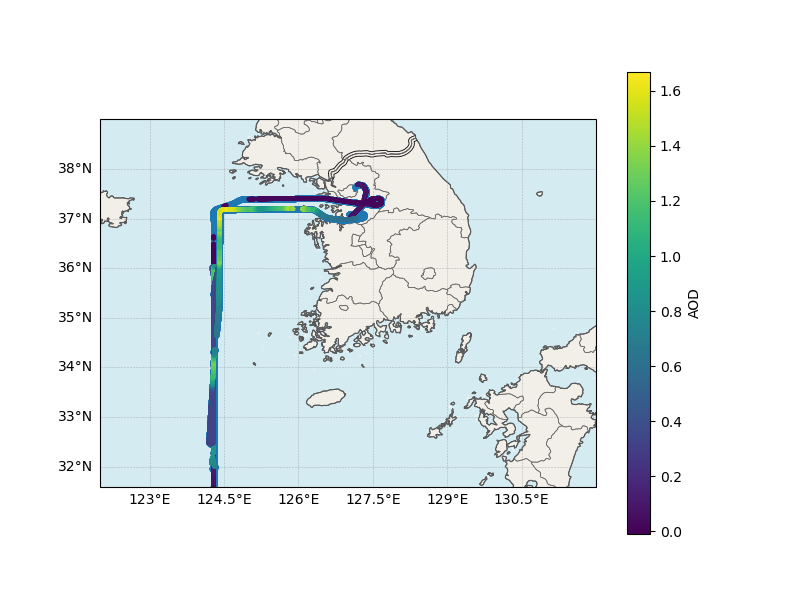

In [98]:
fig,ax,proj = make_map(extent=[122.0,132.0,31.6,39.0])
ax.plot(kor['Lon'],kor['Lat'],'.',zorder=5,transform=proj)
psc = ax.scatter(kor['Lon'],kor['Lat'],5,marker='o',c=kor['tau_aero'][:,400],zorder=20,transform=proj)
plt.colorbar(psc,label='AOD')

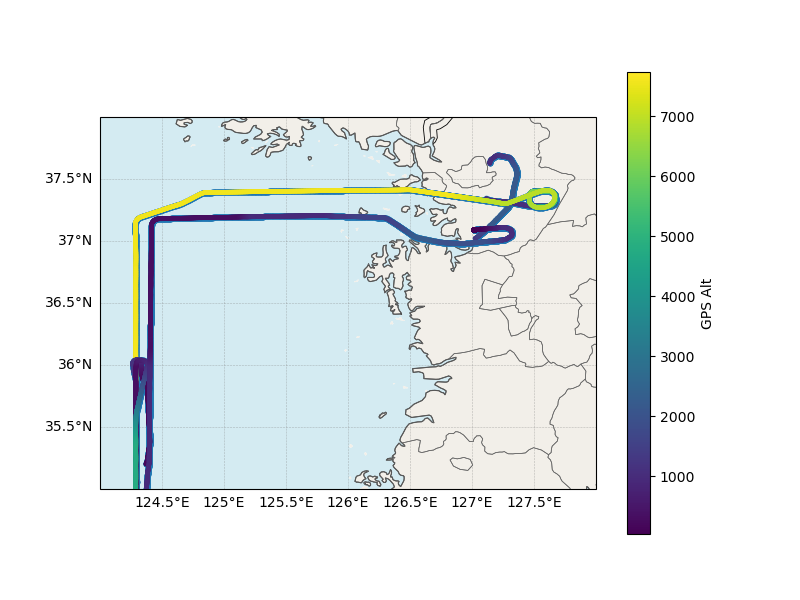

In [99]:
fig,ax,proj = make_map(extent=[124.0,128.0,35,38.0])
ax.plot(kor['Lon'],kor['Lat'],'.',zorder=5,transform=proj)
psc = ax.scatter(kor['Lon'],kor['Lat'],5,marker='o',c=kor['Alt'],zorder=20,transform=proj)
plt.colorbar(psc,label='GPS Alt')

In [119]:
ilandk = 800
icoastk = 23200
ioceank = 8400

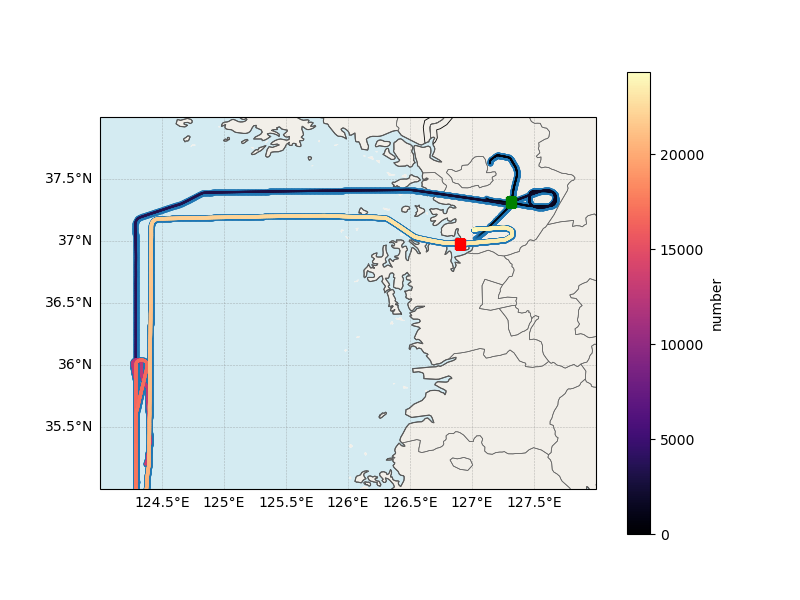

In [120]:
fig,ax,proj = make_map(extent=[124.0,128.0,35,38.0])
ax.plot(kor['Lon'],kor['Lat'],'.',zorder=5,transform=proj)
psc = ax.scatter(kor['Lon'],kor['Lat'],np.arange(len(kor['Alt']))/10000,marker='o',c=np.arange(len(kor['Alt'])),zorder=20,transform=proj,cmap=plt.cm.magma)
ax.scatter(kor['Lon'][ilandk],kor['Lat'][ilandk],60,marker='s',c='g',zorder=25,transform=proj)
ax.scatter(kor['Lon'][icoastk],kor['Lat'][icoastk],60,marker='s',c='r',zorder=25,transform=proj)
ax.scatter(kor['Lon'][ioceank],kor['Lat'][ioceank],60,marker='s',c='b',zorder=25,transform=proj)


plt.colorbar(psc,label='number')

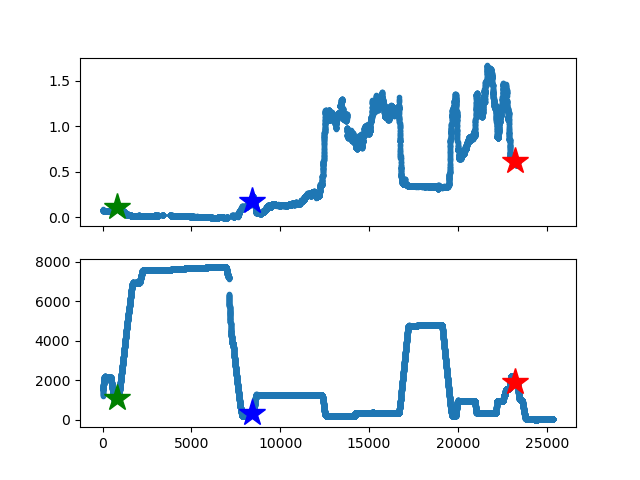

In [121]:
fig,ax = plt.subplots(2,1,sharex=True)
ax[0].plot(kor['tau_aero'][:,400],'.')
ax[0].plot(ilandk,kor['tau_aero'][ilandk,400],'*g',markersize=20)
ax[0].plot(icoastk,kor['tau_aero'][icoastk,400],'*r',markersize=20)
ax[0].plot(ioceank,kor['tau_aero'][ioceank,400],'*b',markersize=20)
ax[1].plot(kor['Alt'],'.')
ax[1].plot(ilandk,kor['Alt'][ilandk],'*g',markersize=20)
ax[1].plot(icoastk,kor['Alt'][icoastk],'*r',markersize=20)
ax[1].plot(ioceank,kor['Alt'][ioceank],'*b',markersize=20)

Text(0.5, 1.0, 'KORUS-AQ 2016-05-21')

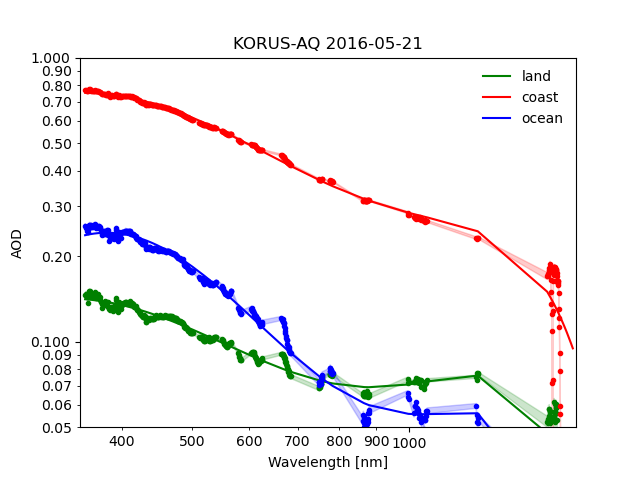

In [123]:
import matplotlib.ticker as ticker

plt.figure()
wvl = kor['w'][kor['aerosolcols'][46:].astype(int)] * 1000
aod = kor['tau_aero'].T[kor['aerosolcols'][46:].astype(int), :]

plot_aod_spp(wvl, aod, ilandk, color='g', deg=20, label='land')
plot_aod_spp(wvl, aod, icoastk, color='r', deg=20, label='coast')
plot_aod_spp(wvl, aod, ioceank, color='b', deg=20, label='ocean')

plt.yscale('log')
plt.xscale('log')
plt.xlim(350, 1700)
plt.ylim(0.05, 1.0)

# Format both major and minor ticks as plain numbers (no scientific notation)
ax = plt.gca()
for axis in [ax.xaxis, ax.yaxis]:
    fmt = ticker.ScalarFormatter()
    fmt.set_scientific(False)
    axis.set_major_formatter(fmt)
    axis.set_minor_formatter(fmt)

plt.legend(frameon=False)
plt.xlabel('Wavelength [nm]')
plt.ylabel('AOD')
plt.title('KORUS-AQ 2016-05-21')


# Now combine the plots into one

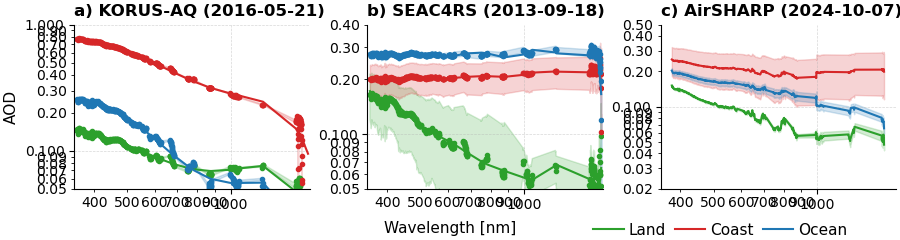

In [165]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# 1. Create a 1x3 layout with shared X-axis and constrained layout to prevent overlaps
fig, axes = plt.subplots(1, 3, figsize=(9, 2.4), sharex=True, constrained_layout=True)

# Colorblind-friendly, publication-grade palette (or keep 'g', 'r', 'b' if preferred)
colors = {'land': '#2ca02c', 'coast': '#d62728', 'ocean': '#1f77b4'}

# --- Panel 1: KORUS-AQ ---
plt.sca(axes[0])
wvl_k = kor['w'][kor['aerosolcols'][46:].astype(int)] * 1000
aod_k = kor['tau_aero'].T[kor['aerosolcols'][46:].astype(int), :]
plot_aod_spp(wvl_k, aod_k, ilandk, color=colors['land'], deg=20, label='Land')
plot_aod_spp(wvl_k, aod_k, icoastk, color=colors['coast'], deg=20, label='Coast')
plot_aod_spp(wvl_k, aod_k, ioceank, color=colors['ocean'], deg=20, label='Ocean')
axes[0].set_ylim(0.05, 1.0)
axes[0].set_title('a) KORUS-AQ (2016-05-21)', loc='left', fontweight='bold')

# --- Panel 2: SEAC4RS ---
plt.sca(axes[1])
wvl_s = seacr['w'][0, seacr['aerosolcols'][0, 46:]] * 1000
aod_s = seacr['tau_aero'].T[seacr['aerosolcols'][0, 46:], :]
plot_aod_spp(wvl_s, aod_s, ilands, color=colors['land'], deg=20, label='Land')
plot_aod_spp(wvl_s, aod_s, icoasts, color=colors['coast'], deg=20, label='Coast')
plot_aod_spp(wvl_s, aod_s, ioceans, color=colors['ocean'], deg=20, label='Ocean')
axes[1].set_ylim(0.05, 0.4)
axes[1].set_title('b) SEAC4RS (2013-09-18)', loc='left', fontweight='bold')

# --- Panel 3: AirSHARP ---
plt.sca(axes[2])
plot_aod_sp(air[b'wavelength'], air[b'AOD'], iland, color=colors['land'], label=f"Land")# ({air_coast[iland]:.1f} km)")
plot_aod_sp(air[b'wavelength'], air[b'AOD'], icoast, color=colors['coast'], label=f"Coast")# ({air_coast[icoast]:.1f} km)")
plot_aod_sp(air[b'wavelength'], air[b'AOD'], iocean, color=colors['ocean'], label=f"Ocean")# ({air_coast[iocean]:.1f} km)")
axes[2].set_ylim(0.02, 0.5)  # Adjust to match AirSHARP's range
axes[2].set_title('c) AirSHARP (2024-10-07)', loc='left', fontweight='bold')
# Keep panel-specific legend here since it contains distance-to-coast metadata
#axes[2].legend(frameon=False, fontsize=9, loc='upper right')

# --- Unified Formatting Across All Panels ---
fmt = ticker.ScalarFormatter()
fmt.set_scientific(False)

for i, ax in enumerate(axes):
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(350, 1700)  # Consistent wavelength range across all 3 panels
    
    # Plain number formatting for major and minor ticks
    for axis in [ax.xaxis, ax.yaxis]:
        axis.set_major_formatter(fmt)
        axis.set_minor_formatter(fmt)
    
    # Clean up visual clutter: subtle grid, remove top/right spines
    ax.grid(True, which='major', linestyle='--', linewidth=0.5, alpha=0.5)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Only put Y-axis label on the leftmost panel
    if i == 0:
        ax.set_ylabel('AOD', fontsize=11)

# Shared X-axis label centered across the entire figure
fig.supxlabel('Wavelength [nm]', fontsize=11)

# Single shared legend for Panels a & b placed cleanly above the plots
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.8, 0.13), ncol=3, frameon=False, fontsize=11,
          columnspacing=0.6,handletextpad=0.3)

plt.show()
#plt.tight_layout()
